# Health Insurance Cashless Claim Approval Prediction

## Project objective
Build a supervised **regression** model that estimates `approved_amount` from claim-time patient, treatment, hospital, billing and policy information.

**Business context:** A hospital submits a cashless claim. The insurer reviews clinical details, documentation, hospital charges and policy terms before approving an amount. This project studies historical patterns; it does not replace an insurer's adjudication process.

**Dataset:** 5,000 records × 41 columns in the supplied CSV.  
**Target:** `approved_amount` (currency amounts are treated as the dataset's INR amounts).

> **Important limitation:** This is an educational case-study dataset. Model predictions are not real insurance decisions, medical advice or fraud findings. Confirm permission before publishing the raw dataset or course material.


## 1. Imports and reproducibility
We use pandas for data analysis, matplotlib/seaborn for charts, and scikit-learn for preprocessing and regression. A fixed random seed makes the model comparison repeatable. The training script is the single source of truth for the preprocessing and model pipeline used by the Streamlit app.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "train_model.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from train_model import prepare_features, build_pipeline, TARGET

DATA_PATH = ROOT / "data" / "cashless_claim_prediction_dataset.csv"
df = pd.read_csv(DATA_PATH)
pd.set_option("display.max_columns", 60)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5000, 41)


,claim_id,patient_id,hospital_id,claim_submitted_date,age,gender,city_tier,bmi,smoker_flag,comorbidity_score,prior_claim_count_2yr,prior_claim_amount_2yr,admission_type,treatment_type,diagnosis_category,severity_level,procedure_count,procedure_complexity_score,icu_days,length_of_stay_days,pre_existing_disease_flag,hospital_type,hospital_tier,network_hospital_flag,hospital_historical_approval_rate,hospital_billing_index,hospital_city_tier,policy_type,policy_tenure_months,sum_insured,remaining_sum_insured,room_rent_limit_per_day,copay_percent,deductible_amount,waiting_period_applicable_flag,claimed_amount,room_charges,doctor_fees,medicine_charges,document_quality_score,approved_amount
0,CLM00003551,PAT000616,HSP0197,2024-08-24,62,Female,3.0,NaN,0.0,1,0,0,Emergency,Non-Surgery,Orthopedic,4,3,3.9,2,8,0,Corporate,A,0,0.695,1.18,1,Floater,22,1000000,1000000,3915.0,10,10000,0,50974,22119,7975,10083,100.0,20662
1,CLM00004880,PAT001780,HSP0151,2024-04-11,38,Male,2.0,29.0,0.0,0,1,51576,Planned,Surgery,ENT,4,5,3.4,1,8,0,Corporate,C,1,0.605,0.90,3,Family,37,800000,788833,5077.0,0,0,0,57113,22148,13163,11712,74.0,35592
2,CLM00000982,PAT000934,HSP0230,2023-07-04,50,Male,2.0,28.9,0.0,1,0,0,Emergency,Non-Surgery,Infectious,1,0,3.4,2,13,1,Corporate,A,0,0.958,1.24,3,Individual,10,2000000,2000000,13989.0,5,1000,0,51824,30179,8293,10292,61.0,48351
3,CLM00004997,PAT001322,HSP0077,2023-06-28,6,Male,1.0,NaN,0.0,2,0,0,Emergency,DayCare,Oncology,4,3,5.5,2,4,0,Corporate,A,1,0.904,1.18,3,Corporate,20,336000,321812,2201.0,0,1000,0,59420,20321,8625,18688,64.0,35995
4,CLM00001759,PAT001541,HSP0114,2025-01-12,58,Male,1.0,23.1,0.0,2,0,0,Planned,Surgery,ENT,4,4,5.1,1,9,1,Corporate,A,1,0.927,1.29,1,Individual,31,100000,67734,1500.0,20,30000,0,105636,38276,23423,22119,96.0,31538


## 2. Understand the business target and variables
Each row is a cashless claim. Features describe the patient, medical treatment, hospital, policy and billed costs. `approved_amount` is the amount approved and is the regression target. IDs identify records/entities and are not treated as numeric predictors.

Before modeling, confirm the precise business meaning, units and timing of each column with the dataset owner. A variable recorded only after an approval decision must not be used to predict that decision.

In [2]:
print("Columns:", len(df.columns))
display(pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "missing": df.isna().sum().values,
    "missing_pct": (df.isna().mean().values * 100).round(2),
    "unique_values": df.nunique(dropna=True).values
}))

Columns: 41


,column,dtype,missing,missing_pct,unique_values
0,claim_id,object,0,0.00,4904
1,patient_id,object,0,0.00,1947
2,hospital_id,object,0,0.00,259
3,claim_submitted_date,object,0,0.00,1083
4,age,int64,0,0.00,94
5,gender,object,0,0.00,6
6,city_tier,float64,49,0.98,3
7,bmi,float64,221,4.42,250
8,smoker_flag,float64,124,2.48,2
9,comorbidity_score,int64,0,0.00,9


## 3. Data quality: shape, types and summary statistics
`info()` reveals data types and non-null counts. `describe()` summarizes numeric ranges. These checks help identify unexpected types, impossible values and highly variable cost fields.

In [3]:
df.info()
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 41 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   claim_id                           5000 non-null   object 
 1   patient_id                         5000 non-null   object 
 2   hospital_id                        5000 non-null   object 
 3   claim_submitted_date               5000 non-null   object 
 4   age                                5000 non-null   int64  
 5   gender                             5000 non-null   object 
 6   city_tier                          4951 non-null   float64
 7   bmi                                4779 non-null   float64
 8   smoker_flag                        4876 non-null   float64
 9   comorbidity_score                  5000 non-null   int64  
 10  prior_claim_count_2yr              5000 non-null   int64  
 11  prior_claim_amount_2yr             5000 non-null   int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
claim_id,5000,4904,CLM00000024,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
patient_id,5000,1947,PAT001099,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hospital_id,5000,259,HSP0128,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
claim_submitted_date,5000,1083,2024-02-03,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5000.0,NaN,NaN,NaN,41.82,19.659301,0.0,30.0,43.0,54.0,150.0
gender,5000,6,Male,2631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_tier,4951.0,NaN,NaN,NaN,1.899414,0.808029,1.0,1.0,2.0,3.0,3.0
bmi,4779.0,NaN,NaN,NaN,25.078301,5.374184,-3.5,22.1,25.0,27.9,80.0
smoker_flag,4876.0,NaN,NaN,NaN,0.174733,0.379778,0.0,0.0,0.0,0.0,1.0
comorbidity_score,5000.0,NaN,NaN,NaN,1.6822,1.362341,0.0,1.0,1.0,2.0,8.0


## 4. Missing-value analysis
Missingness can indicate incomplete forms, data capture limitations or fields that do not apply. We report counts and percentages but do not impute the entire dataset here. The model pipeline imputes using statistics learned from training folds only, preventing information from the holdout set leaking into preprocessing.

,missing_count,missing_pct
bmi,221,4.42
document_quality_score,174,3.48
smoker_flag,124,2.48
hospital_billing_index,99,1.98
room_rent_limit_per_day,74,1.48
city_tier,49,0.98


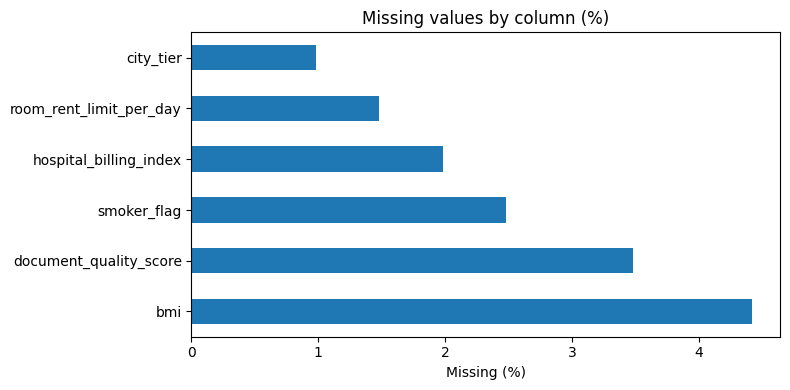

In [4]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values("missing_pct", ascending=False)
display(missing)
if not missing.empty:
    missing["missing_pct"].plot(kind="barh", figsize=(8,4), title="Missing values by column (%)")
    plt.xlabel("Missing (%)")
    plt.tight_layout()
    plt.show()

## 5. Duplicate and identifier checks
Exact duplicate rows are usually accidental and are removed by the training script. Repeated `claim_id` values require investigation; they are not automatically deleted because the reason for repetition is unknown. Repeated patient/hospital IDs are expected when entities have multiple claims. IDs are excluded from model predictors to reduce memorization.

In [5]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate claim_id rows:", df["claim_id"].duplicated().sum())
print("Unique patients:", df["patient_id"].nunique())
print("Unique hospitals:", df["hospital_id"].nunique())
display(df[df["claim_id"].duplicated(keep=False)].sort_values("claim_id").head(10))

Exact duplicate rows: 96
Duplicate claim_id rows: 96
Unique patients: 1947
Unique hospitals: 259


,claim_id,patient_id,hospital_id,claim_submitted_date,age,gender,city_tier,bmi,smoker_flag,comorbidity_score,prior_claim_count_2yr,prior_claim_amount_2yr,admission_type,treatment_type,diagnosis_category,severity_level,procedure_count,procedure_complexity_score,icu_days,length_of_stay_days,pre_existing_disease_flag,hospital_type,hospital_tier,network_hospital_flag,hospital_historical_approval_rate,hospital_billing_index,hospital_city_tier,policy_type,policy_tenure_months,sum_insured,remaining_sum_insured,room_rent_limit_per_day,copay_percent,deductible_amount,waiting_period_applicable_flag,claimed_amount,room_charges,doctor_fees,medicine_charges,document_quality_score,approved_amount
4405,CLM00000024,PAT002048,HSP0190,2024-06-14,0,Male,1.0,24.0,0.0,0,0,0,Planned,Surgery,Neurology,3,2,2.7,0,12,0,Corporate,A,0,0.898,1.29,1,Family,68,500000,500000,4261.0,5,0,0,93766,37568,22388,18238,NaN,63704
854,CLM00000024,PAT002048,HSP0190,2024-06-14,0,Male,1.0,24.0,0.0,0,0,0,Planned,Surgery,Neurology,3,2,2.7,0,12,0,Corporate,A,0,0.898,1.29,1,Family,68,500000,500000,4261.0,5,0,0,93766,37568,22388,18238,NaN,63704
3306,CLM00000030,PAT001268,HSP0001,2025-12-25,53,Male,2.0,19.3,0.0,2,1,27837,Emergency,Surgery,ENT,4,2,8.2,0,7,0,Trust,A,1,0.980,1.00,3,Corporate,14,560000,560000,4850.0,10,0,0,89338,31856,19394,17170,74.0,62005
3991,CLM00000030,PAT001268,HSP0001,2025-12-25,53,Male,2.0,19.3,0.0,2,1,27837,Emergency,Surgery,ENT,4,2,8.2,0,7,0,Trust,A,1,0.980,1.00,3,Corporate,14,560000,560000,4850.0,10,0,0,89338,31856,19394,17170,74.0,62005
1489,CLM00000066,PAT000493,HSP0157,2025-04-28,82,Male,1.0,24.8,1.0,6,1,41434,Planned,Maternity,Renal,4,3,8.0,1,14,1,Corporate,B,1,0.650,1.12,3,Individual,37,100000,100000,1500.0,0,10000,1,115920,56916,21195,22883,75.0,52711
623,CLM00000066,PAT000493,HSP0157,2025-04-28,82,Male,1.0,24.8,1.0,6,1,41434,Planned,Maternity,Renal,4,3,8.0,1,14,1,Corporate,B,1,0.650,1.12,3,Individual,37,100000,100000,1500.0,0,10000,1,115920,56916,21195,22883,75.0,52711
611,CLM00000080,PAT001797,HSP0106,2025-06-11,48,Male,1.0,21.1,1.0,5,1,20614,Planned,Non-Surgery,Orthopedic,4,0,6.2,2,6,0,Corporate,A,1,0.804,1.15,1,Family,23,200000,200000,1500.0,30,20000,0,54957,21078,8186,10955,81.0,8158
972,CLM00000080,PAT001797,HSP0106,2025-06-11,48,Male,1.0,21.1,1.0,5,1,20614,Planned,Non-Surgery,Orthopedic,4,0,6.2,2,6,0,Corporate,A,1,0.804,1.15,1,Family,23,200000,200000,1500.0,30,20000,0,54957,21078,8186,10955,81.0,8158
2436,CLM00000085,PAT000780,HSP0087,2024-07-17,54,Female,1.0,30.7,1.0,6,2,33798,Emergency,DayCare,ENT,1,1,6.6,0,3,0,Govt,C,1,0.482,0.98,1,Family,36,500000,473377,4281.0,20,2000,0,18051,5717,2958,3969,83.0,8898
266,CLM00000085,PAT000780,HSP0087,2024-07-17,54,Female,1.0,30.7,1.0,6,2,33798,Emergency,DayCare,ENT,1,1,6.6,0,3,0,Govt,C,1,0.482,0.98,1,Family,36,500000,473377,4281.0,20,2000,0,18051,5717,2958,3969,83.0,8898


## 6. Domain-specific validity checks
We flag values that deserve review, rather than removing every statistical outlier. Age above 100 may be unusual but not impossible. BMI outside a broad plausible range and co-pay outside 0–100 are treated as missing in the training feature-preparation function. Negative or zero claimed amounts and negative target amounts are excluded from training because they do not represent a normal positive claim request/approval. Confirm these rules with the data owner before production use.

In [6]:
checks = {
    "age_below_0_or_above_120": int(((df["age"] < 0) | (df["age"] > 120)).sum()),
    "bmi_nonpositive_or_above_100": int(((df["bmi"] <= 0) | (df["bmi"] > 100)).sum()),
    "copay_outside_0_100": int(((df["copay_percent"] < 0) | (df["copay_percent"] > 100)).sum()),
    "claimed_amount_nonpositive": int((df["claimed_amount"] <= 0).sum()),
    "negative_approved_amount": int((df["approved_amount"] < 0).sum())
}
display(pd.Series(checks, name="rows_to_review").to_frame())

,rows_to_review
age_below_0_or_above_120,14
bmi_nonpositive_or_above_100,16
copay_outside_0_100,6
claimed_amount_nonpositive,20
negative_approved_amount,0


## 7. Univariate analysis: numerical distributions
Histograms show the shape of numeric variables. Medical cost data may be right-skewed because a small number of complex cases can be expensive. A skewed distribution is not, by itself, a reason to delete records.

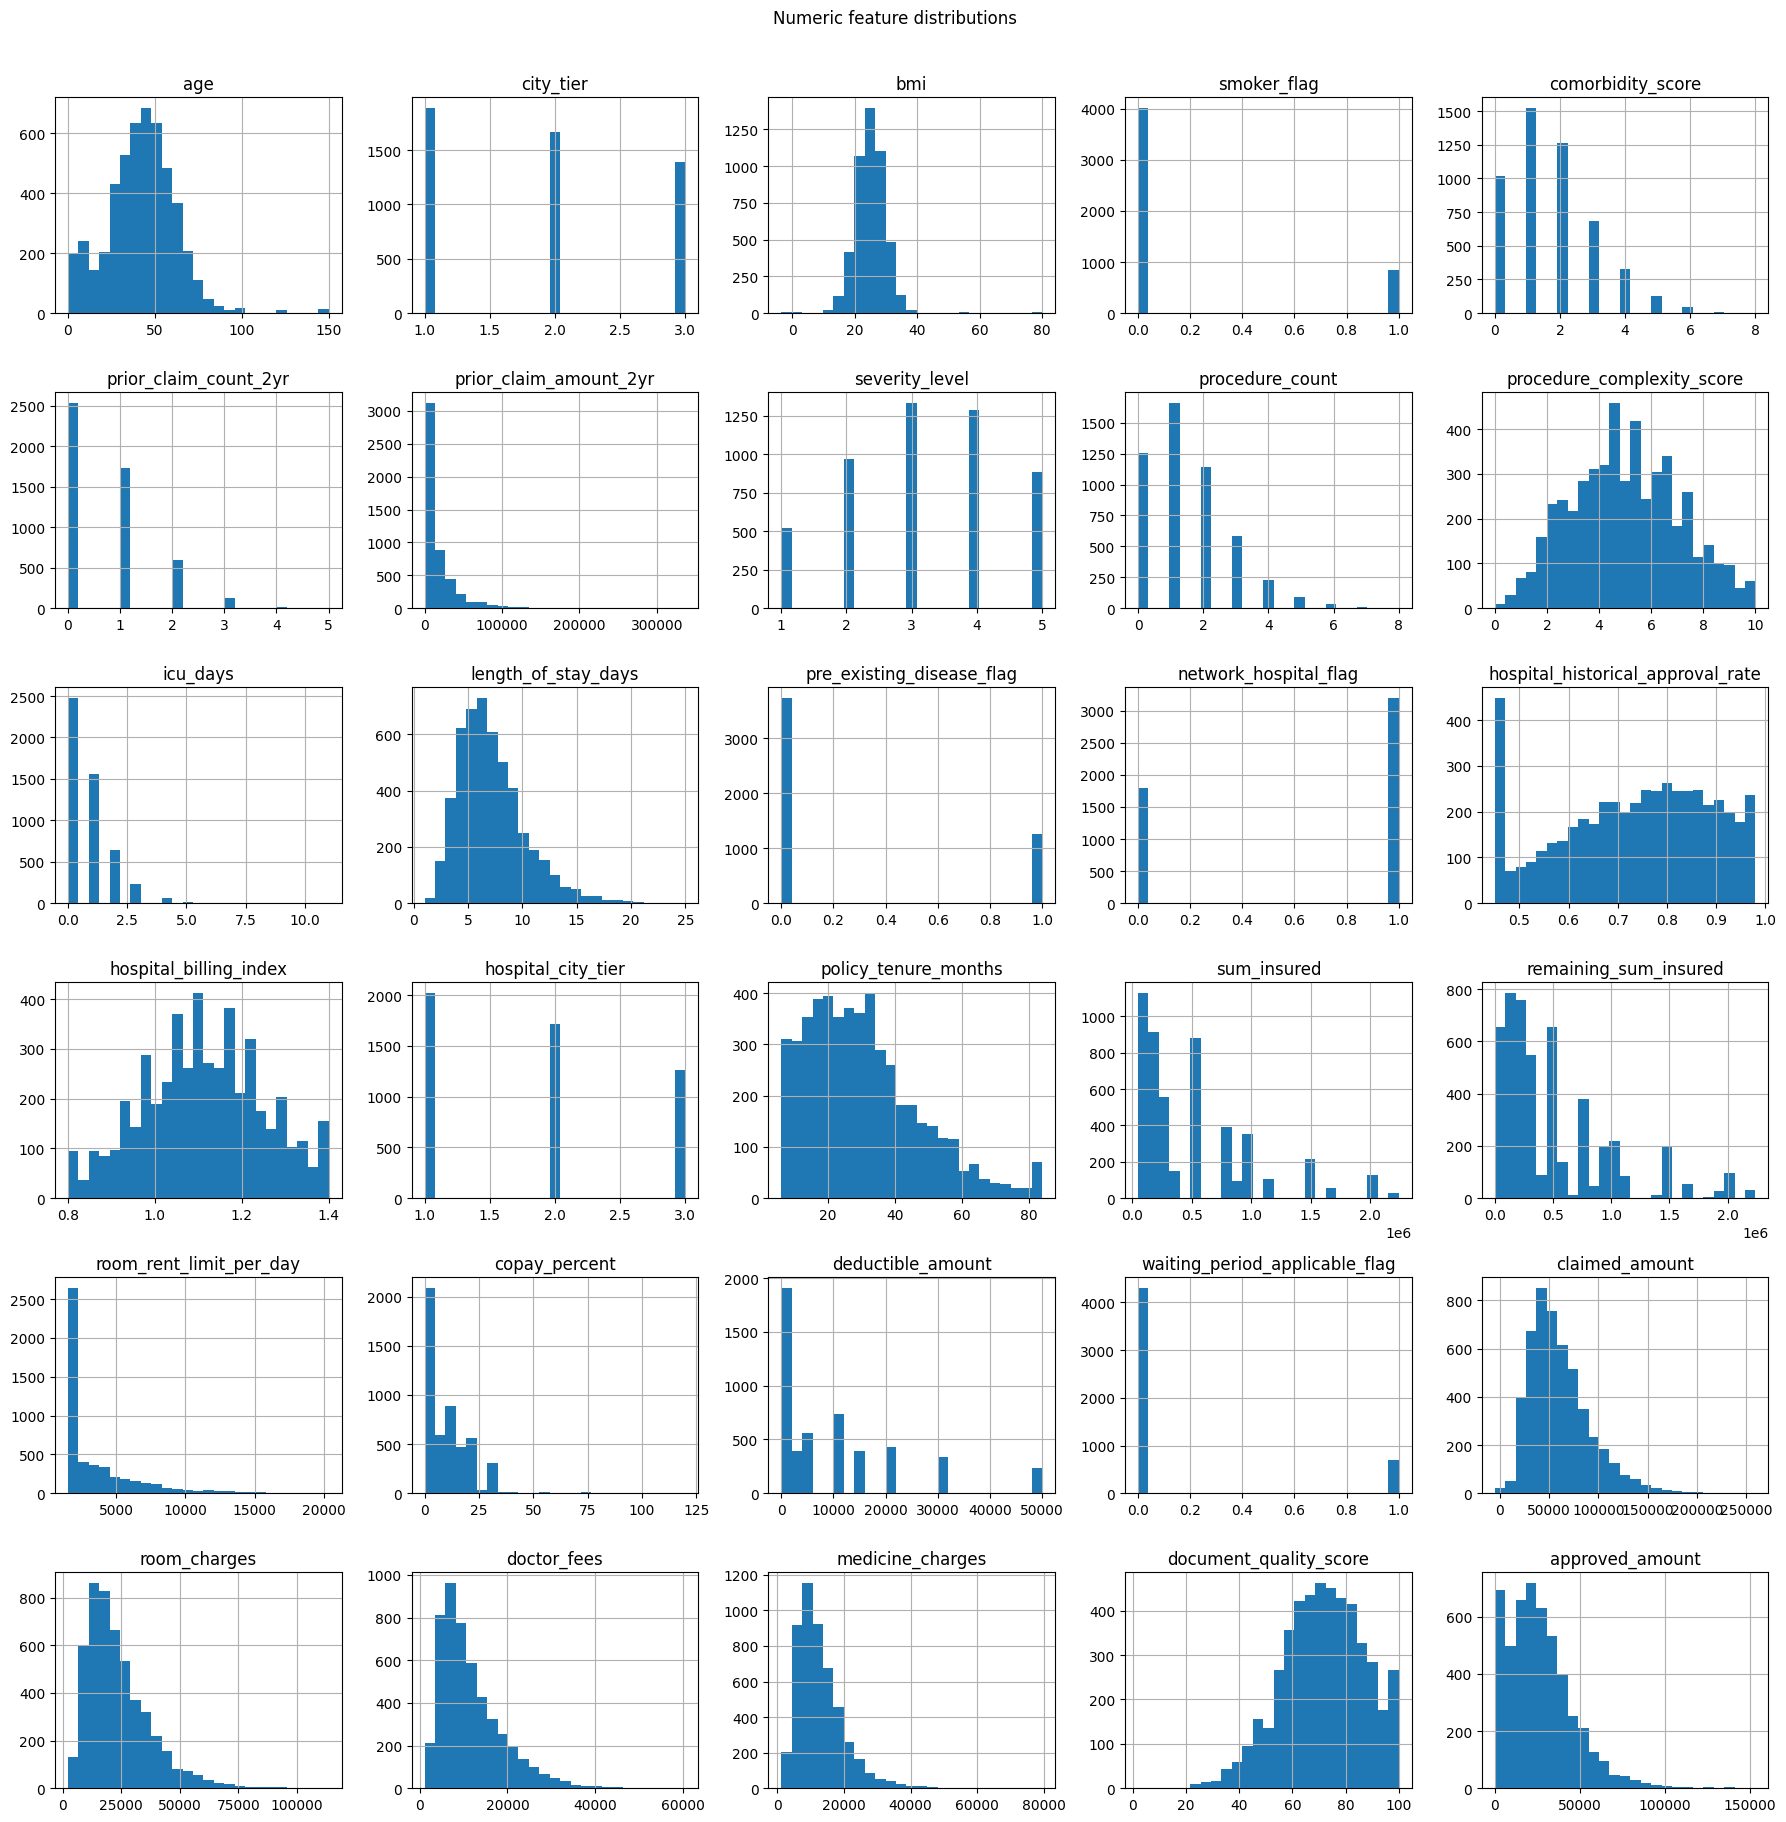

In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].hist(figsize=(18,18), bins=25)
plt.suptitle("Numeric feature distributions", y=1.01)
plt.tight_layout()
plt.show()

## 8. Target analysis: approved amount
We inspect the target distribution, median, spread and IQR-based outlier share. IQR outliers are kept because unusually high-value claims may be legitimate and important to the insurance use case.

,approved_amount
count,5000.000000
mean,26672.628800
std,19632.937744
min,0.000000
25%,12910.000000
50%,23958.000000
75%,36986.750000
max,153439.000000


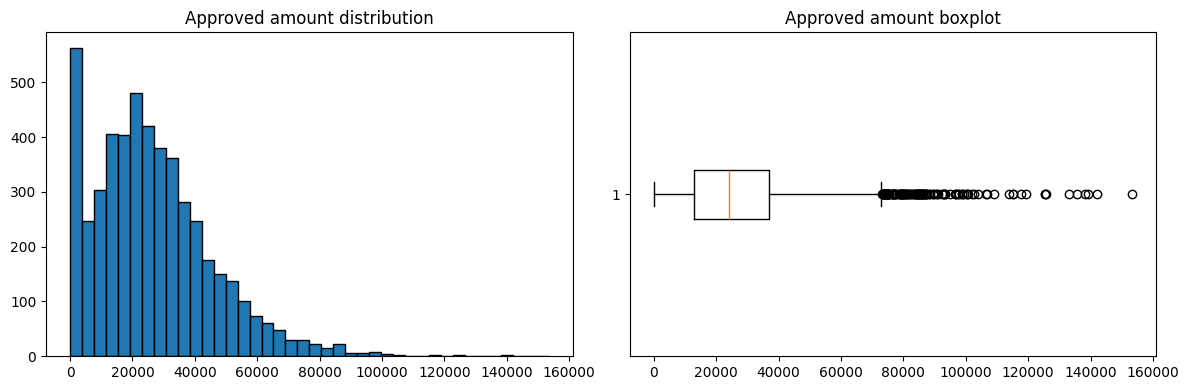

Target skewness: 1.145
IQR outlier share (%): 2.66


In [8]:
display(df["approved_amount"].describe().to_frame("approved_amount"))
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].hist(df["approved_amount"], bins=40, edgecolor="black")
axes[0].set_title("Approved amount distribution")
axes[1].boxplot(df["approved_amount"], vert=False)
axes[1].set_title("Approved amount boxplot")
plt.tight_layout()
plt.show()
q1, q3 = df["approved_amount"].quantile([.25,.75])
iqr = q3-q1
outlier_share = ((df["approved_amount"] < q1-1.5*iqr) | (df["approved_amount"] > q3+1.5*iqr)).mean()
print("Target skewness:", round(df["approved_amount"].skew(),3))
print("IQR outlier share (%):", round(outlier_share*100,2))

## 9. Business relationship: claimed vs approved
This scatter plot examines whether higher requested amounts tend to receive higher approvals. Correlation is descriptive, not causal. The fraction of claims with approval below the requested amount can reflect policy limits, co-pay, deductibles, non-payable items or partial/denied claims; it does not identify the reason for an individual case.

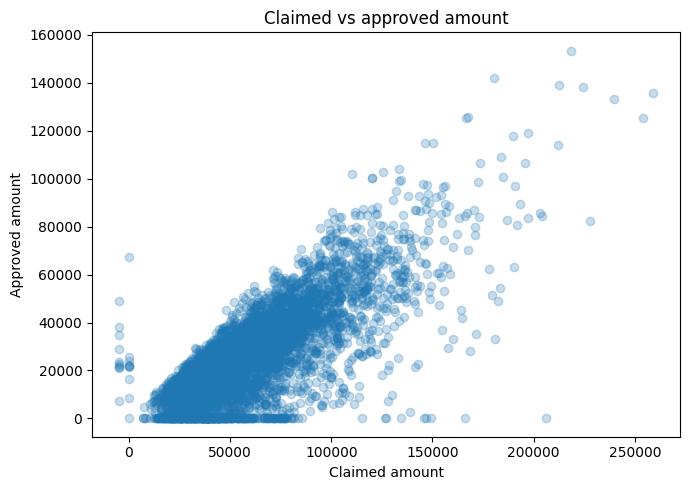

Correlation: 0.767
Approved < claimed (%): 99.6


In [9]:
plt.figure(figsize=(7,5))
plt.scatter(df["claimed_amount"], df["approved_amount"], alpha=.25)
plt.xlabel("Claimed amount")
plt.ylabel("Approved amount")
plt.title("Claimed vs approved amount")
plt.tight_layout()
plt.show()
print("Correlation:", round(df[["claimed_amount","approved_amount"]].corr().iloc[0,1],3))
print("Approved < claimed (%):", round((df["approved_amount"] < df["claimed_amount"]).mean()*100,2))

## 10. Business relationship: severity and approved amount
We compare median approvals by severity level. This is a useful descriptive question from the case-study brief. Differences across groups do not prove that severity alone causes a higher approval.

,count,median,mean
severity_level,,,
1,522,17958.0,21146.157088
2,972,21065.5,23355.305556
3,1336,21924.0,24660.650449
4,1288,28263.5,30023.202640
5,882,28654.5,31753.944444


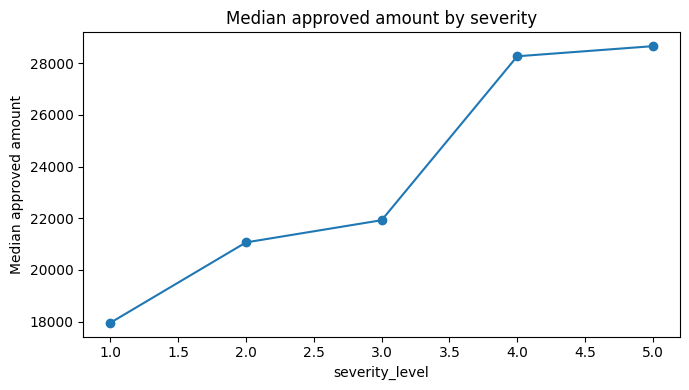

In [10]:
severity_summary = df.groupby("severity_level")["approved_amount"].agg(["count","median","mean"])
display(severity_summary)
severity_summary["median"].plot(marker="o", figsize=(7,4), title="Median approved amount by severity")
plt.ylabel("Median approved amount")
plt.tight_layout()
plt.show()

## 11. Feature engineering
We add row-level features that can be calculated for a new claim: room/doctor/medicine charge shares, claimed amount relative to insured cover and remaining cover, excess over remaining cover, and room-limit exposure across length of stay.

We deliberately do **not** calculate patient/hospital claim frequency by counting all rows before splitting. That would use information from future/holdout records and may not be available at prediction time. Historical approval rate and document-quality timing must be validated with the domain owner for leakage.

In [11]:
feature_preview = prepare_features(df.drop(columns=["approved_amount"]))
print("Raw predictor count:", df.drop(columns=["approved_amount"]).shape[1])
print("After feature engineering and ID removal:", feature_preview.shape[1])
display(feature_preview.head())

Raw predictor count: 40
After feature engineering and ID removal: 46


,age,gender,city_tier,bmi,smoker_flag,comorbidity_score,prior_claim_count_2yr,prior_claim_amount_2yr,admission_type,treatment_type,diagnosis_category,severity_level,procedure_count,procedure_complexity_score,icu_days,length_of_stay_days,pre_existing_disease_flag,hospital_type,hospital_tier,network_hospital_flag,hospital_historical_approval_rate,hospital_billing_index,hospital_city_tier,policy_type,policy_tenure_months,sum_insured,remaining_sum_insured,room_rent_limit_per_day,copay_percent,deductible_amount,waiting_period_applicable_flag,claimed_amount,room_charges,doctor_fees,medicine_charges,document_quality_score,claim_month,claim_quarter,claim_dayofweek,room_charge_share,doctor_fee_share,medicine_charge_share,claim_to_sum_insured_ratio,claim_to_remaining_cover_ratio,claim_excess_over_remaining_cover,stay_room_limit_exposure
0,62.0,Female,3.0,NaN,0.0,1,0,0,Emergency,Non-Surgery,Orthopedic,4,3,3.9,2,8,0,Corporate,A,0,0.695,1.18,1,Floater,22,1000000,1000000,3915.0,10.0,10000,0,50974,22119,7975,10083,100.0,8,3,5,0.433927,0.156452,0.197807,0.050974,0.050974,-949026,31320.0
1,38.0,Male,2.0,29.0,0.0,0,1,51576,Planned,Surgery,ENT,4,5,3.4,1,8,0,Corporate,C,1,0.605,0.90,3,Family,37,800000,788833,5077.0,0.0,0,0,57113,22148,13163,11712,74.0,4,2,3,0.387793,0.230473,0.205067,0.071391,0.072402,-731720,40616.0
2,50.0,Male,2.0,28.9,0.0,1,0,0,Emergency,Non-Surgery,Infectious,1,0,3.4,2,13,1,Corporate,A,0,0.958,1.24,3,Individual,10,2000000,2000000,13989.0,5.0,1000,0,51824,30179,8293,10292,61.0,7,3,1,0.582336,0.160022,0.198595,0.025912,0.025912,-1948176,181857.0
3,6.0,Male,1.0,NaN,0.0,2,0,0,Emergency,DayCare,Oncology,4,3,5.5,2,4,0,Corporate,A,1,0.904,1.18,3,Corporate,20,336000,321812,2201.0,0.0,1000,0,59420,20321,8625,18688,64.0,6,2,2,0.341989,0.145153,0.314507,0.176845,0.184642,-262392,8804.0
4,58.0,Male,1.0,23.1,0.0,2,0,0,Planned,Surgery,ENT,4,4,5.1,1,9,1,Corporate,A,1,0.927,1.29,1,Individual,31,100000,67734,1500.0,20.0,30000,0,105636,38276,23423,22119,96.0,1,1,6,0.362339,0.221733,0.209389,1.056360,1.559571,37902,13500.0


## 12. Modeling design: avoid leakage
The training script performs these steps:
- Removes exact duplicate rows and rows with missing/negative target values.
- Sorts claims by submission date and reserves the latest 20% as a holdout test set.
- Fits imputers and one-hot encoders inside a scikit-learn Pipeline. These steps are re-fitted inside each cross-validation fold.
- Drops claim, patient and hospital IDs.
- Selects a model using expanding-window time-series expanding-window time-series cross-validation on the training portion only.
- Evaluates the selected model once on the later-date holdout.

A chronological holdout approximates predicting future claims, assuming the timestamps are meaningful. For a stricter evaluation, consider patient-grouped or hospital-grouped validation as well.

In [12]:
from train_model import main
print("Run `python train_model.py` from the project root to train, compare and save the model.")
print("The script prints cross-validation scores and final holdout MAE, RMSE and R².")

Run `python train_model.py` from the project root to train, compare and save the model.
The script prints cross-validation scores and final holdout MAE, RMSE and R².


## 13. Model comparison and final holdout metrics
After running `python train_model.py`, the script writes:
- `artifacts/model_comparison.csv`: cross-validation comparison on training data.
- `artifacts/metrics.json`: final holdout metrics for the selected model.
- `artifacts/test_predictions.csv`: actual, predicted and residual values.
- `artifacts/cashless_claim_model.joblib`: fitted preprocessing + model pipeline.

MAE and RMSE are in the target's currency units. R² measures the proportion of target variance explained on the holdout set. Lower MAE/RMSE and higher R² are generally preferred; business tolerance matters more than a single score.

In [13]:
metrics_path = ROOT / "artifacts" / "metrics.json"
comparison_path = ROOT / "artifacts" / "model_comparison.csv"
if metrics_path.exists():
    print("Final holdout metrics:")
    print(json.dumps(json.loads(metrics_path.read_text()), indent=2))
    display(pd.read_csv(comparison_path))
else:
    print("Artifacts not found yet. Run `python train_model.py` from the project root.")

Final holdout metrics:
{
  "selected_model": "RandomForest",
  "test_MAE": 3236.84274855241,
  "test_RMSE": 4659.85280860374,
  "test_R2": 0.934031419793611,
  "train_rows": 3923,
  "test_rows": 981,
  "feature_count_before_encoding": 46,
  "test_split": "chronological 80/20 by claim_submitted_date"
}


,model,CV_MAE_mean,CV_RMSE_mean,CV_R2_mean
0,RandomForest,4120.088203,6462.701038,0.890881
1,GradientBoosting,4338.261679,6504.582012,0.894275
2,ExtraTrees,4027.635862,6614.597844,0.887462
3,Ridge,4601.726709,7594.608302,0.850665
4,DecisionTree,5762.827839,9062.454583,0.790263


## 14. Residual diagnostics
Residual = actual approved amount − predicted approved amount. A residual plot can reveal systematic under/over-prediction or error that grows with claim size. It is important to inspect errors, not just summary metrics.

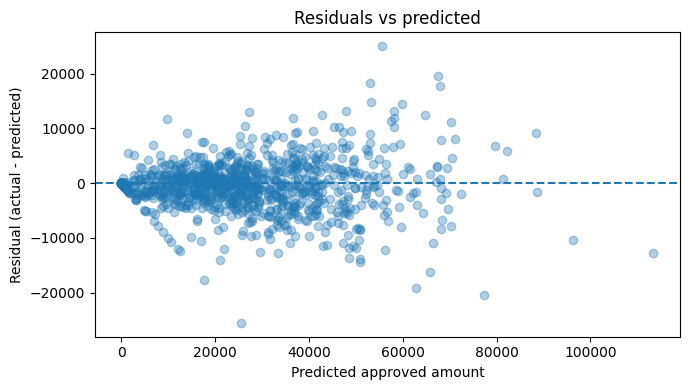

,count,mean,std,min,25%,50%,75%,max
actual,981.0,26207.272171,18152.025628,0.000000,13563.000000,24091.000000,37043.000000,100728.000000
predicted,981.0,26708.324587,17464.547872,0.000000,13818.585649,24693.932977,37339.104444,113415.402484
residual,981.0,-501.052416,4635.199658,-25527.857908,-2687.629581,-321.155568,1647.319206,25039.205014


In [14]:
pred_path = ROOT / "artifacts" / "test_predictions.csv"
if pred_path.exists():
    pred = pd.read_csv(pred_path)
    plt.figure(figsize=(7,4))
    plt.scatter(pred["predicted"], pred["residual"], alpha=.35)
    plt.axhline(0, linestyle="--")
    plt.xlabel("Predicted approved amount")
    plt.ylabel("Residual (actual - predicted)")
    plt.title("Residuals vs predicted")
    plt.tight_layout()
    plt.show()
    display(pred[["actual","predicted","residual"]].describe().T)
else:
    print("Run the training script to generate test predictions.")

## 16. Model interpretation: feature importance
For the selected tree-based model, the training script saves impurity-based feature importance after preprocessing. These scores describe how the fitted model used features; they are not causal effects, approval rules or proof of fairness. Correlated features can share or distort importance.

,feature,importance
0,numeric__claimed_amount,0.436155
1,numeric__deductible_amount,0.197687
2,numeric__room_charges,0.152656
3,numeric__doctor_fees,0.058634
4,numeric__remaining_sum_insured,0.028568
5,numeric__stay_room_limit_exposure,0.020827
6,numeric__copay_percent,0.018021
7,numeric__medicine_charges,0.017075
8,numeric__claim_excess_over_remaining_cover,0.007260
9,numeric__room_rent_limit_per_day,0.006711


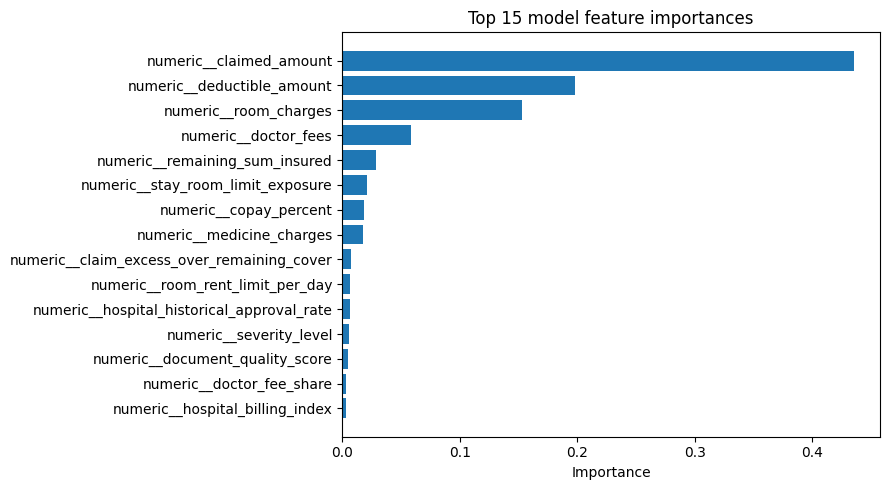

In [15]:
importance_path = ROOT / "artifacts" / "feature_importance.csv"
if importance_path.exists():
    importance = pd.read_csv(importance_path).head(15).sort_values("importance")
    display(importance.sort_values("importance", ascending=False))
    plt.figure(figsize=(9,5))
    plt.barh(importance["feature"], importance["importance"])
    plt.title("Top 15 model feature importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance is generated for tree-based models by train_model.py.")

## 17. Limitations and next steps
1. Verify feature availability timing, especially `hospital_historical_approval_rate` and `document_quality_score`.
2. Confirm the business rules used for invalid values and currency amounts.
3. Evaluate performance by severity, hospital tier, policy type and claim-size bands.
4. Test on independent, authorized data and consider grouped validation to test generalization to unseen patients/hospitals.
5. Compare model predictions with explicit policy-rule baselines.
6. Add SHAP only after checking stability and fairness.

**Key learning:** A strong project is not only about a high R². It must avoid leakage, use an honest holdout, explain its errors and communicate limitations clearly.